In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [2]:
DATA_PATH = Path(
    "../data/raw/seg_train"
)

print(
    DATA_PATH.exists()
)

True


In [3]:
class_names = []

for folder in DATA_PATH.iterdir():

    if folder.is_dir():

        class_names.append(
            folder.name
        )

class_names.sort()

print(
    class_names
)

print(
    "Number of classes:",
    len(class_names)
)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


In [4]:
image_extensions = [
    ".jpg",
    ".jpeg",
    ".png"
]

class_counts = {}

for class_name in class_names:

    class_path = (
        DATA_PATH
        / class_name
    )

    count = 0

    for file in class_path.iterdir():

        if file.suffix.lower() in image_extensions:

            count += 1

    class_counts[
        class_name
    ] = count

print(
    class_counts
)

{'buildings': 2628, 'forest': 2745, 'glacier': 2957, 'mountain': 3037, 'sea': 2784, 'street': 2883}


In [5]:
distribution_df = pd.DataFrame(
    class_counts.items(),
    columns=[
        "class",
        "image_count"
    ]
)

distribution_df

,class,image_count
0,buildings,2628
1,forest,2745
2,glacier,2957
3,mountain,3037
4,sea,2784
5,street,2883


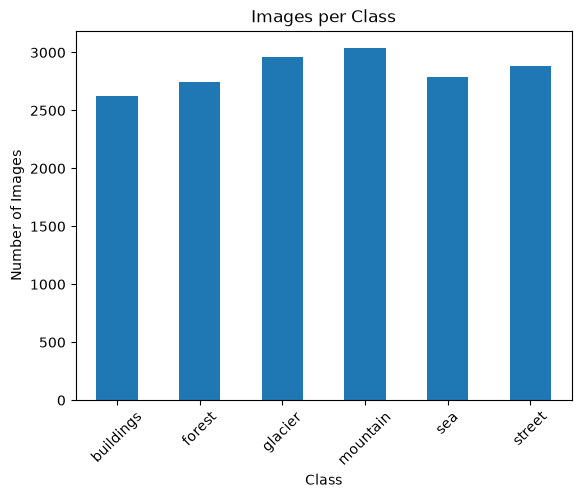

In [6]:
distribution_df.plot(
    x="class",
    y="image_count",
    kind="bar",
    legend=False
)

plt.title(
    "Images per Class"
)

plt.xlabel(
    "Class"
)

plt.ylabel(
    "Number of Images"
)

plt.xticks(
    rotation=45
)

plt.show()

In [7]:
image_data = []

for class_name in class_names:

    class_path = (
        DATA_PATH
        / class_name
    )

    for file_path in class_path.iterdir():

        if file_path.suffix.lower() in image_extensions:

            try:

                image = Image.open(
                    file_path
                )

                width, height = (
                    image.size
                )

                image_data.append({
                    "class": class_name,
                    "filename": file_path.name,
                    "width": width,
                    "height": height,
                    "format": image.format,
                    "mode": image.mode
                })

                image.close()

            except:

                print(
                    "Problem with:",
                    file_path
                )

In [10]:
images_df = pd.DataFrame(
    image_data
)

images_df.head()

print(
    "Total images:",
    len(images_df)
)

print(
    images_df[
        [
            "width",
            "height"
        ]
    ].describe()
)

Total images: 17034
         width        height
count  17034.0  17034.000000
mean     150.0    149.907773
std        0.0      1.991765
min      150.0     72.000000
25%      150.0    150.000000
50%      150.0    150.000000
75%      150.0    150.000000
max      150.0    150.000000


In [11]:
images_df[
    "resolution"
] = (
    images_df["width"].astype(str)
    + "x"
    + images_df["height"].astype(str)
)

In [12]:
print(
    images_df[
        "resolution"
    ].value_counts().head(10)
)

resolution
150x150    16979
150x113        7
150x135        3
150x111        3
150x108        2
150x141        2
150x136        2
150x110        2
150x149        2
150x143        2
Name: count, dtype: int64


In [13]:
print(
    images_df[
        "format"
    ].value_counts()
)

format
JPEG    17034
Name: count, dtype: int64


In [14]:
print(
    images_df[
        "mode"
    ].value_counts()
)

mode
RGB    17034
Name: count, dtype: int64


In [15]:
small_images = images_df[
    (
        images_df["width"] < 100
    )
    |
    (
        images_df["height"] < 100
    )
]

print(
    "Small images:",
    len(small_images)
)

Small images: 6


In [16]:
broken_images = []

for class_name in class_names:

    class_path = (
        DATA_PATH
        / class_name
    )

    for file_path in class_path.iterdir():

        if file_path.suffix.lower() in image_extensions:

            try:

                image = Image.open(
                    file_path
                )

                image.verify()

                image.close()

            except:

                broken_images.append(
                    file_path
                )

In [17]:
print(
    "Broken images:",
    len(broken_images)
)

Broken images: 0


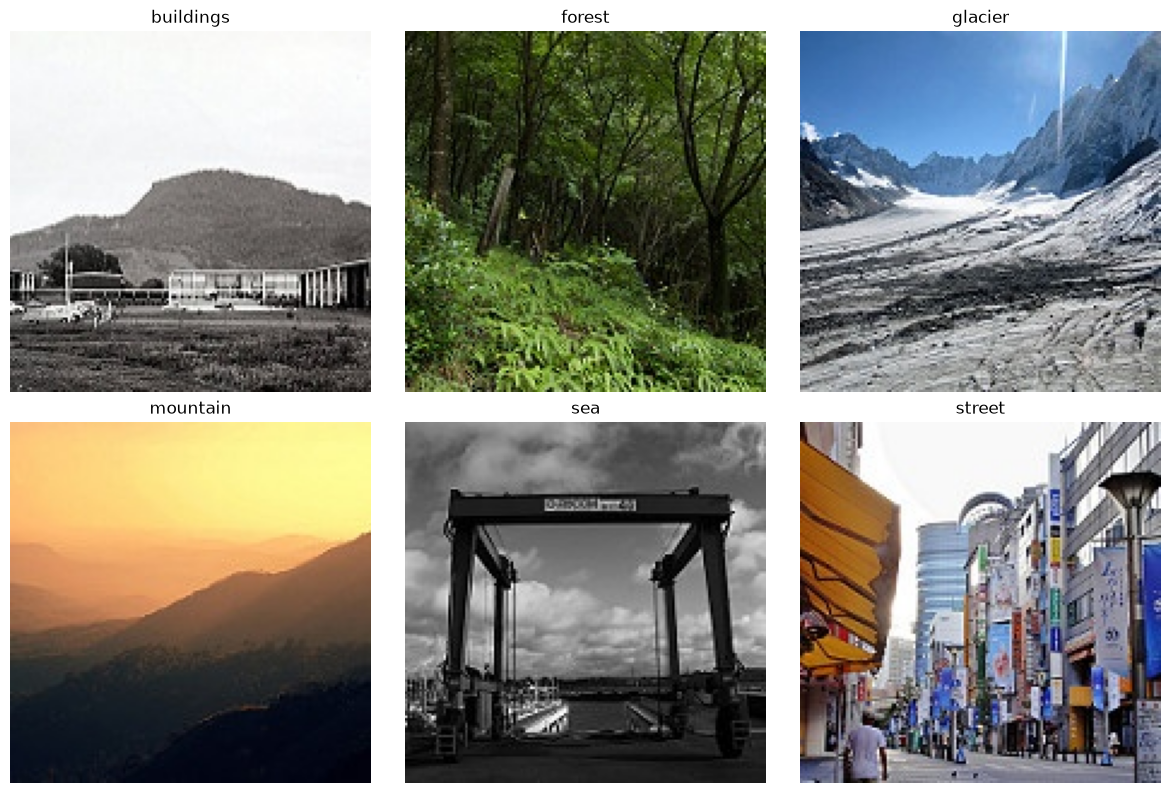

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes = axes.flatten()

for i, class_name in enumerate(class_names):

    class_path = DATA_PATH / class_name

    images = list(class_path.glob("*.jpg"))

    image = Image.open(images[0])

    axes[i].imshow(image)
    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [21]:
OUTPUT_PATH = Path(
    "../data/processed"
)

OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True
)

images_df.to_csv(
    OUTPUT_PATH
    / "image_metadata.csv",
    index=False
)

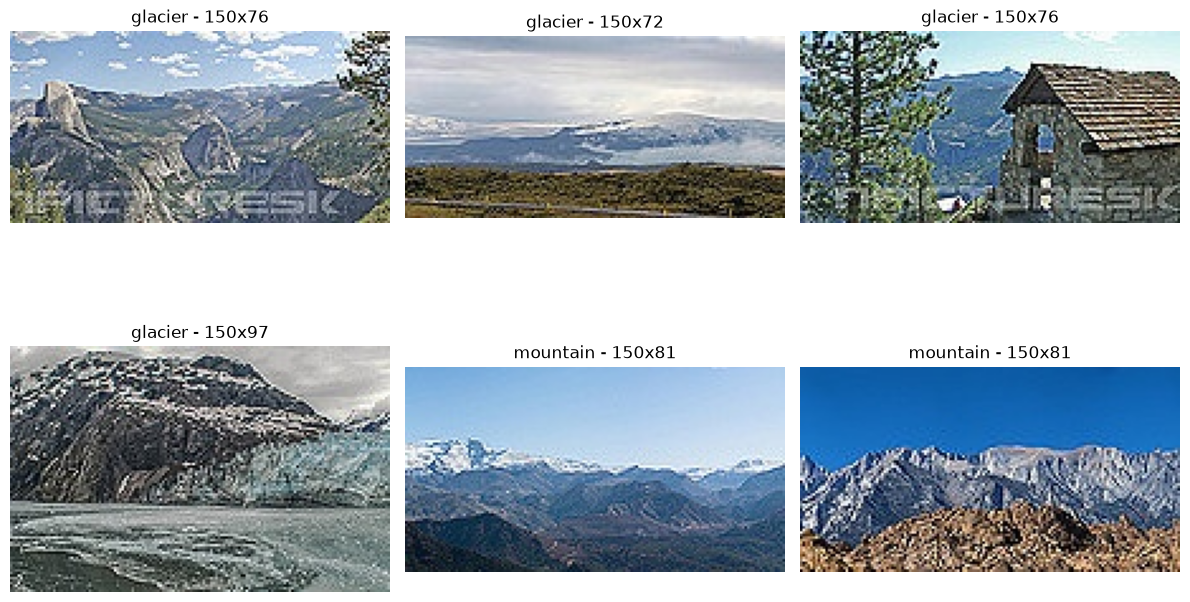

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes = axes.flatten()

for i in range(len(small_images)):

    row = small_images.iloc[i]

    image_path = (
        DATA_PATH
        / row["class"]
        / row["filename"]
    )

    image = Image.open(image_path)

    axes[i].imshow(image)
    axes[i].set_title(
        f'{row["class"]} - {row["width"]}x{row["height"]}'
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()